# Group Health IBNR with Completion Factors

This example follows the six-step IBNR estimate in the
[model solution](https://www.soa.org/globalassets/assets/files/edu/2022/spring/solutions/edu-2022-spring-solutions-ghfvu.pdf) to question 1(c) of the Society of Actuaries'
Spring 2022 GH FVU exam. The solution lists the reading GHFV-103-16, Health
Reserves, as a source for question 1.

IBNR here is incurred claims less claims paid to date, for each incurred
month of 2021, valued December 31, 2021. A completion factor is the share of
a month's incurred claims paid by a given lag.

The solution prints the age-to-age factors, paid claims and members but not
the claims triangle itself, so every input below is a figure printed in the
solution.

In [1]:
import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import chainladder as cl

## Steps 1 and 2: age-to-age factors and six-month averages

The solution prints the age-to-age factors, to two decimals, for incurred
months June 2020 to November 2021 at lags 0 to 12. A simple average of link
ratios does not depend on the size of each row, so a triangle that starts
each row at 1.0 and multiplies through the printed factors has the same link
ratios (`ratios.link_ratio`). `Development(n_periods=6, average="simple")`
averages the latest six at each lag.

In [2]:
printed_factors = """
2020-06 23.51 1.46 1.05 1.02 1.01 1.01 1.00 1.00 1.00 1.00 1.00 1.00 1.00
2020-07 30.27 1.29 1.08 1.08 1.02 1.01 1.00 1.00 1.01 1.00 1.00 1.00 1.00
2020-08  9.28 1.40 1.06 1.03 1.01 1.01 1.00 1.00 1.00 1.00 1.00 1.00 1.00
2020-09 47.12 1.13 1.04 1.02 1.01 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00
2020-10  5.75 1.44 1.12 1.03 1.01 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00
2020-11 22.29 1.30 1.03 1.01 1.01 1.01 1.01 1.00 1.00 1.00 1.00 1.00 1.00
2020-12 14.91 1.21 1.04 1.05 1.01 1.04 1.00 1.00 1.01 1.01 1.00 1.00
2021-01 10.90 1.50 1.07 1.05 1.03 1.00 1.01 1.01 1.01 1.00 1.00
2021-02 15.82 1.57 1.09 1.02 1.02 1.00 1.01 1.00 1.00 1.00
2021-03  9.23 1.48 1.03 1.01 1.03 1.01 1.00 1.00 1.00
2021-04 20.73 1.28 1.03 1.06 1.01 1.00 1.01 1.00
2021-05 17.03 1.20 1.07 1.02 1.01 1.01 1.00
2021-06 16.51 1.59 1.03 1.01 1.00 1.00
2021-07 23.11 1.25 1.11 1.02 1.01
2021-08 14.52 1.37 1.04 1.08
2021-09 11.23 1.14 1.07
2021-10  4.83 1.69
2021-11 21.94
"""

records = []
for line in printed_factors.strip().splitlines():
    month, *factors = line.split()
    origin = pd.Period(month, freq="M")
    for lag, value in enumerate(np.cumprod([1.0, *map(float, factors)])):
        records.append((origin.start_time, (origin + lag).end_time, value))
ratios = cl.Triangle(
    pd.DataFrame(records, columns=["incurred", "paid", "index"]),
    origin="incurred",
    valuation="paid",
    columns="index",
    cumulative=True,
)

printed_by_lag = """
lag average completion
  0  15.356    4.2
  1   1.374   64.5
  2   1.057   88.7
  3   1.031   93.8
  4   1.014   96.7
  5   1.005   98.1
  6   1.005   98.6
  7   1.003   99.1
  8   1.002   99.4
  9   1.003   99.6
 10   1.001   99.9
 11   1.001   99.9
 12   1.000  100.0
"""
by_lag = pd.read_csv(io.StringIO(printed_by_lag), sep=r"\s+", index_col="lag")
printed_averages = by_lag["average"].to_numpy()

latest_six = cl.Development(n_periods=6, average="simple").fit(ratios)
averages = pd.DataFrame(
    {
        "chainladder": latest_six.ldf_.values[0, 0, 0, :13].round(4),
        "printed": printed_averages,
    },
    index=by_lag.index,
)
averages["difference"] = (averages["chainladder"] - averages["printed"]).round(4)
print(f"Largest difference: {averages['difference'].abs().max():.4f}")
averages

Largest difference: 0.0023


,chainladder,printed,difference
lag,,,
0,15.3567,15.356,0.0007
1,1.3733,1.374,-0.0007
2,1.0583,1.057,0.0013
3,1.0333,1.031,0.0023
4,1.0133,1.014,-0.0007
5,1.0033,1.005,-0.0017
6,1.0050,1.005,0.0000
7,1.0017,1.003,-0.0013
8,1.0033,1.002,0.0013


The averages are within 0.0023 of the printed three-decimal ones. Rounding
the factors to two decimals and the averages to three allows up to 0.0055,
so the gaps fit a solution that averaged the unrounded triangle. The steps
below use the printed averages.

## Steps 3 and 4: completion factors

Claims are complete 12 months after the incurred month, so the completion
factor at lag 12 is 1.0, and each earlier lag's factor is the next one
divided by that lag's average. Chainladder counts monthly ages from 1, so
lag 0 is age 1. `DevelopmentConstant` takes the averages for lags 0 to 10.
The lag 11 average goes in `TailConstant`, because January 2021, the oldest
month reserved, is at lag 11 on December 31, 2021. `pct_reported_` then
holds the completion factors.

In [3]:
printed_2021 = """
month   members paid_to_date incurred    ibnr
2021-01   12227      2548319  2549802    1482
2021-02   12201      2187520  2190341    2821
2021-03   12130      2361225  2370435    9209
2021-04   11986      2237437  2251387   13950
2021-05   11927      2385024  2406479   21455
2021-06   11814      2196919  2228197   31278
2021-07   11787      2502042  2550951   48909
2021-08   11689      2466086  2550060   83974
2021-09   11731      2688921  2867962  179041
2021-10   11843      2193388  2473189  279802
2021-11   11902      1283817  1989471  705654
2021-12   11844        96378  2214706 2118328
"""
data = pd.read_csv(io.StringIO(printed_2021), sep=r"\s+", index_col="month")
printed_total = 3_495_902

tri = cl.Triangle(
    data.assign(incurred=data.index, paid="2021-12-31"),
    origin="incurred",
    valuation="paid",
    columns=["paid_to_date", "members"],
    cumulative=True,
).val_to_dev()


def completion_model(averages, tail):
    """Average factors for lags 0 to 10, and the lag 11 factor as the tail."""
    patterns = dict(zip(range(1, 12), averages[:11]))
    return cl.Pipeline([
        ("dev", cl.DevelopmentConstant(patterns=patterns, style="ldf")),
        ("tail", cl.TailConstant(tail)),
    ]).fit_transform(tri["paid_to_date"])


paid = completion_model(printed_averages, printed_averages[11])
pd.DataFrame({
    "chainladder (%)": (100 * paid.pct_reported_.values[0, 0, 0, :12]).round(1),
    "printed (%)": by_lag["completion"].iloc[:12],
})

,chainladder (%),printed (%)
lag,,
0,4.2,4.2
1,64.6,64.5
2,88.7,88.7
3,93.8,93.8
4,96.7,96.7
5,98.0,98.1
6,98.5,98.6
7,99.0,99.1
8,99.3,99.4


Seven of the twelve completion factors differ from the printed percentages
by 0.1 point, and the reconciliation below shows why. Only December 2021,
at lag 0, is under 30% complete, so it is the one month on the projection
method.

## Step 5: trended PMPM

For the projection method, the solution divides 2019–2020 claims by
2019–2020 members to get a cost per member per month (PMPM). It trends the
PMPM at 10% a year for 23.5 months, from January 1, 2020, the middle of the
experience period, to December 15, 2021, the middle of the month being
reserved.

In [4]:
pmpm = 42_872_648 / 276_327
trended_pmpm = pmpm * 1.10 ** (23.5 / 12)
print(f"PMPM {pmpm:.2f}, trended PMPM {trended_pmpm:.2f}")

PMPM 155.15, trended PMPM 186.99


## Step 6: IBNR by month

`VotingChainladder` picks a method for each incurred month. Months at least
30% complete use `Chainladder`, which divides paid to date by the completion
factor. The rest use `ExpectedLoss` with the trended PMPM as `apriori` and
members as `sample_weight`, so incurred claims are PMPM times members.

In [5]:
def ibnr_by_month(paid):
    completion = paid.pct_reported_.values[0, 0, 0, :12][::-1]  # January: lag 11
    projected = completion < 0.30
    model = cl.VotingChainladder(
        estimators=[
            ("development", cl.Chainladder()),
            ("projection", cl.ExpectedLoss(apriori=trended_pmpm)),
        ],
        weights=[(0, 1) if p else (1, 0) for p in projected],
    ).fit(paid, sample_weight=tri["members"].latest_diagonal)
    return pd.DataFrame(
        {
            "completion (%)": (100 * completion).round(1),
            "method": np.where(projected, "projection", "development"),
            # A month with no IBNR comes back as NaN.
            "IBNR": np.nan_to_num(model.ibnr_.values[0, 0, :, 0]),
        },
        index=data.index,
    )


result = ibnr_by_month(paid)
total = round(result["IBNR"].sum())
print(f"Total IBNR {total:,}, printed {printed_total:,}")
print(f"Difference {total - printed_total:,} ({total / printed_total - 1:.2%})")
print(f"December's share of the total: {result['IBNR'].iloc[-1] / total:.0%}")
result.assign(**{
    "IBNR": result["IBNR"].round().astype(int),
    "printed IBNR": data["ibnr"],
})

Total IBNR 3,508,051, printed 3,495,902
Difference 12,149 (0.35%)
December's share of the total: 60%


,completion (%),method,IBNR,printed IBNR
month,,,,
2021-01,99.9,development,2548,1482
2021-02,99.8,development,4377,2821
2021-03,99.5,development,11823,9209
2021-04,99.3,development,15700,13950
2021-05,99.0,development,23941,21455
2021-06,98.5,development,33148,31278
2021-07,98.0,development,50450,48909
2021-08,96.7,development,84947,83974
2021-09,93.8,development,178850,179041


December's IBNR, 2,118,328, matches the solution. The total, 3,508,051, is
12,149 (0.35%) above the printed 3,495,902.

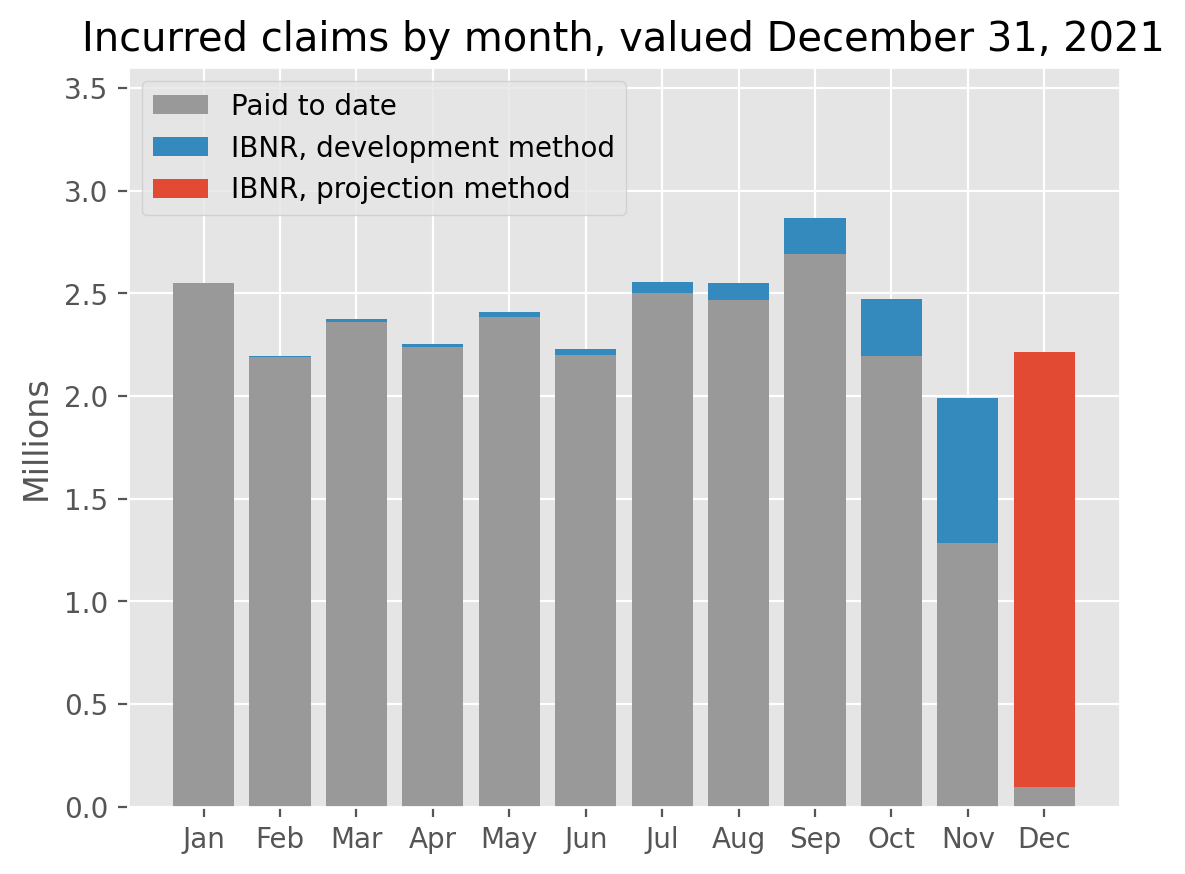

In [6]:
plt.style.use("ggplot")
%config InlineBackend.figure_format = 'retina'

fig, ax = plt.subplots()
months = pd.PeriodIndex(data.index, freq="M").strftime("%b")
ax.bar(months, data["paid_to_date"] / 1e6, color="0.6", label="Paid to date")
for method, color in [("development", "C1"), ("projection", "C0")]:
    rows = (result["method"] == method).to_numpy()
    ax.bar(
        months[rows],
        result["IBNR"][rows] / 1e6,
        bottom=data["paid_to_date"][rows] / 1e6,
        color=color,
        label=f"IBNR, {method} method",
    )
ax.set(
    title="Incurred claims by month, valued December 31, 2021",
    ylabel="Millions",
    ylim=(0, 3.6),
)
ax.legend(loc="upper left");

Each bar is one incurred month of 2021: paid to date in gray, with IBNR on
top in blue for the development method and red for the projection method.
IBNR is at most 279,229 a month through October, then 704,709 in November
and 2,118,328 in December, the projected month, which holds 60% of the
total.

## Reconciling the total

The solution also prints incurred claims, so paid to date divided by
incurred claims gives the completion factors it used at lags 1 to 11.
December is projected, so its lag 0 factor is not implied.

In [7]:
implied = (data["paid_to_date"] / data["incurred"]).to_numpy()[::-1]  # lags 0-11
implied_averages = np.append(
    printed_averages[0], np.append(implied[2:] / implied[1:-1], 1 / implied[-1])
)
lags = by_lag.index[1:12]
check = pd.DataFrame(
    {
        "implied completion (%)": (100 * implied[1:]).round(3),
        "printed completion (%)": by_lag["completion"].loc[lags],
        "implied average": implied_averages[1:].round(6),
        "printed average": by_lag["average"].loc[lags],
    },
    index=lags,
)
implied_result = ibnr_by_month(completion_model(implied_averages, implied_averages[11]))
print(
    "Implied completion rounds to the printed:",
    np.array_equal((100 * implied[1:]).round(1), by_lag["completion"].loc[lags]),
)
print(
    "Implied averages round to the printed:",
    np.array_equal(implied_averages[1:].round(3), by_lag["average"].loc[lags]),
)
print(f"Total IBNR with the implied averages: {implied_result['IBNR'].sum():,.0f}")
print(f"Printed monthly IBNR added up: {data['ibnr'].sum():,}")
check

Implied completion rounds to the printed: True
Implied averages round to the printed: True
Total IBNR with the implied averages: 3,495,904
Printed monthly IBNR added up: 3,495,903


,implied completion (%),printed completion (%),implied average,printed average
lag,,,,
1,64.531,64.5,1.374335,1.374
2,88.687,88.7,1.057174,1.057
3,93.757,93.8,1.031462,1.031
4,96.707,96.7,1.014226,1.014
5,98.083,98.1,1.005236,1.005
6,98.596,98.6,1.005195,1.005
7,99.108,99.1,1.002744,1.003
8,99.380,99.4,1.002325,1.002
9,99.611,99.6,1.002608,1.003


Both checks pass, while the three-decimal averages round to different
percentages at seven lags. So the solution most likely carried unrounded
averages, and rounding them to three decimals accounts for the gap: with the
implied averages the total is 3,495,904. The printed monthly amounts add to
3,495,903 against a printed total of 3,495,902, so the last two dollars come
from rounding in the printed figures.

## Two common mistakes

The solution's commentary names two common mistakes: averaging an earlier
six months rather than the latest six, and setting the completion factor to
1.0 at lag 11 rather than lag 12. It does not say which earlier months, so
the code takes the earliest six incurred months, June to November 2020, and
compares them with the latest six, both from the two-decimal triangle of
step 1.

In [8]:
earliest_six = cl.Development(average="simple").fit(ratios[ratios.origin <= "2020-11"])
earliest = earliest_six.ldf_.values[0, 0, 0, :13]
latest = latest_six.ldf_.values[0, 0, 0, :13]
runs = {
    "printed averages": (printed_averages, printed_averages[11]),
    "printed averages, lag 11 set to 1.0": (printed_averages, 1.0),
    "latest six, two decimals": (latest, latest[11]),
    "earliest six, two decimals": (earliest, earliest[11]),
}
totals = (
    pd
    .Series(
        {
            name: ibnr_by_month(completion_model(*run))["IBNR"].sum()
            for name, run in runs.items()
        },
        name="total IBNR",
    )
    .round()
    .astype(int)
)
for run, base in [(1, 0), (3, 2), (2, 0)]:
    change = totals.iloc[run] - totals.iloc[base]
    print(f"{totals.index[run]}: {change:+,} against {totals.index[base]}")
totals

printed averages, lag 11 set to 1.0: -26,414 against printed averages
earliest six, two decimals: -163,258 against latest six, two decimals
latest six, two decimals: -81,935 against printed averages


printed averages                       3508051
printed averages, lag 11 set to 1.0    3481637
latest six, two decimals               3426116
earliest six, two decimals             3262858
Name: total IBNR, dtype: int64

Setting lag 11 to 1.0 multiplies every completion factor by 1.001, the
lag 11 average, so January has no IBNR and the total falls by 26,414.
Averaging the earliest six months lowers the total by 163,258. The
latest-six total from two-decimal factors, 3,426,116, is itself 81,935 below
the total from the printed averages. Those factors are too coarse to set
the reserve, so here they only compare the two windows.